This notebook provides examples to go along with the [textbook](https://underactuated.csail.mit.edu/acrobot.html).  I recommend having both windows open, side-by-side!


In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "underactuated[all]>=2026.9.8"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 987.8/987.8 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.5/38.5 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.4/15.4 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 57.9 MB/s eta 0:00:00


In [2]:
import numpy as np
from pydrake.all import (
    AddMultibodyPlantSceneGraph,
    ControllabilityMatrix,
    DiagramBuilder,
    LeafSystem,
    Linearize,
    LinearQuadraticRegulator,
    MeshcatVisualizer,
    Parser,
    Simulator,
)

from underactuated import ConfigureParser, running_as_notebook
from underactuated.meshcat_utils import MeshcatSliders, StartMeshcat

In [3]:
# Start the visualizer (run this cell only once, each instance consumes a port)
meshcat = StartMeshcat()

<IPython.core.display.Javascript object>

Or run DisplayMeshcat(meshcat) to embed it in this notebook.


# Dynamics of the Cart-Pole

Use the slider in the MeshCat controls to apply force to the cart.
最后记录时间：10.000 秒
最后记录的状态 [x, theta, xdot, thetadot]：
[-4.52502367  0.40276271 -1.07611711  3.99416802]


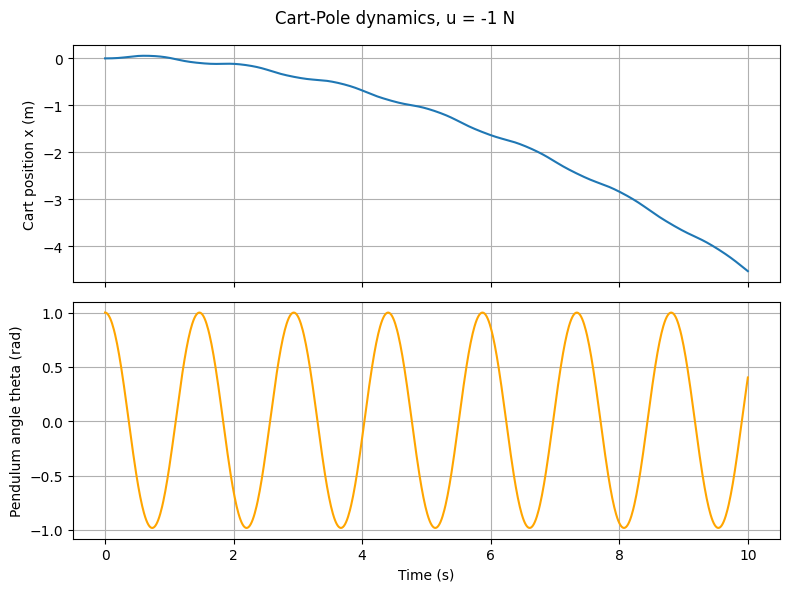

In [7]:
# TODO(russt): Generalize this to a generic gamepad system.


class GamepadTeleop(LeafSystem):
    def __init__(self, meshcat):
        LeafSystem.__init__(self)
        self._meshcat = meshcat
        port = self.DeclareVectorOutputPort("left_stick_x", 1, self.OutputLeftStick)
        # The gamepad has undeclared state.  For now, we accept it,
        # and simply disable caching on the output port.
        port.disable_caching_by_default()

    def CreateStickDeadzone(self, x, y):
        stick = np.array([x, y])
        deadzone = 0.3
        m = np.linalg.norm(stick)
        if m < deadzone:
            return np.array([0, 0])
        over = (m - deadzone) / (1 - deadzone)
        return stick * over / m

    def OutputLeftStick(self, context, output):
        gamepad = self._meshcat.GetGamepad()

        # https://beej.us/blog/data/javascript-gamepad/

        left = self.CreateStickDeadzone(gamepad.axes[0], gamepad.axes[1])
        output[0] = 10 * left[0]


def cartpole_demo():
    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=0.0)
    parser = Parser(plant)
    ConfigureParser(parser)
    parser.AddModelsFromUrl("package://underactuated/models/cartpole.urdf")
    plant.Finalize()

    meshcat.Delete()
    meshcat.Set2dRenderMode(xmin=-2.5, xmax=2.5, ymin=-1.0, ymax=2.5)
    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    if meshcat.GetGamepad().index != None:
        print("Gamepad teleop enabled. Use the left stick to apply force to the cart.")
        gamepad_teleop = builder.AddSystem(GamepadTeleop(meshcat))
        builder.Connect(
            gamepad_teleop.get_output_port(), plant.get_actuation_input_port()
        )
    else:
        print("Use the slider in the MeshCat controls to apply force to the cart.")
        meshcat.AddSlider(
            "u",
            min=-5,
            max=5,
            step=0.1,
            value=-1.0,
            decrement_keycode="ArrowLeft",
            increment_keycode="ArrowRight",
        )
        force_system = builder.AddSystem(MeshcatSliders(meshcat, ["u"]))
        builder.Connect(
            force_system.get_output_port(), plant.get_actuation_input_port()
        )
    from pydrake.all import LogVectorOutput

    logger = LogVectorOutput(plant.get_state_output_port(), builder)
    diagram = builder.Build()

    # Set up a simulator to run this diagram
    simulator = Simulator(diagram)
    context = simulator.get_mutable_context()

    # Set the initial conditions (x, theta, xdot, thetadot)
    context.SetContinuousState([0, 1, 0, 0])

    # if running_as_notebook:  # Then we're not just running as a test on CI.
    #     simulator.set_target_realtime_rate(1.0)

    #     print("Press 'Stop Simulation' in MeshCat to continue.")
    #     meshcat.AddButton("Stop Simulation", "Escape")
    #     while meshcat.GetButtonClicks("Stop Simulation") < 1:
    #         simulator.AdvanceTo(simulator.get_context().get_time() + 1.0)

    # else:
    #     simulator.AdvanceTo(0.1)
    simulator.set_target_realtime_rate(1.0)
    simulator.AdvanceTo(10.0)


    meshcat.DeleteAddedControls()
        # 读取记录的数据
    log = logger.FindLog(simulator.get_context())
    times = log.sample_times().copy()
    states = log.data().copy()

    print(f"最后记录时间：{times[-1]:.3f} 秒")
    print("最后记录的状态 [x, theta, xdot, thetadot]：")
    print(states[:, -1])

    import matplotlib.pyplot as plt

    # 上图：小车位置；下图：摆杆角度
    fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

    axes[0].plot(times, states[0, :])
    axes[0].set_ylabel("Cart position x (m)")
    axes[0].grid(True)

    axes[1].plot(times, states[1, :], color="orange")
    axes[1].set_ylabel("Pendulum angle theta (rad)")
    axes[1].set_xlabel("Time (s)")
    axes[1].grid(True)

    fig.suptitle("Cart-Pole dynamics, u = -1 N")
    fig.tight_layout()
    fig.savefig("cartpole_u_minus1.png", dpi=200, bbox_inches="tight")
    plt.show()


cartpole_demo()

# LQR for the Cart-Pole

In [ ]:
def cartpole_balancing_example():
    def UprightState():
        state = (0, np.pi, 0, 0)
        return state

    def Controllability(plant):
        context = plant.CreateDefaultContext()
        plant.get_actuation_input_port().FixValue(context, [0])
        plant.SetPositionsAndVelocities(context, UprightState())

        linearized_plant = Linearize(
            plant,
            context,
            input_port_index=plant.get_actuation_input_port().get_index(),
            output_port_index=plant.get_state_output_port().get_index(),
        )
        print(linearized_plant.A())
        print(linearized_plant.B())
        print(
            f"The singular values of the controllability matrix are: {np.linalg.svd(ControllabilityMatrix(linearized_plant), compute_uv=False)}"
        )

    def BalancingLQR(plant):
        # Design an LQR controller for stabilizing the CartPole around the upright.
        # Returns a (static) AffineSystem that implements the controller (in
        # the original CartPole coordinates).

        context = plant.CreateDefaultContext()
        plant.get_actuation_input_port().FixValue(context, [0])

        plant.SetPositionsAndVelocities(context, UprightState())

        Q = np.diag((10.0, 10.0, 1.0, 1.0))
        R = np.array([1])

        # MultibodyPlant has many (optional) input ports, so we must pass the
        # input_port_index to LQR.
        return LinearQuadraticRegulator(
            plant,
            context,
            Q,
            R,
            input_port_index=plant.get_actuation_input_port().get_index(),
        )

    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=0)
    parser = Parser(plant)
    ConfigureParser(parser)
    parser.AddModelsFromUrl("package://underactuated/models/cartpole.urdf")
    plant.Finalize()

    controller = builder.AddSystem(BalancingLQR(plant))
    builder.Connect(plant.get_state_output_port(), controller.get_input_port(0))
    builder.Connect(controller.get_output_port(0), plant.get_actuation_input_port())

    # Setup visualization
    meshcat.Delete()
    meshcat.Set2dRenderMode(xmin=-2.5, xmax=2.5, ymin=-1.0, ymax=2.5)
    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    diagram = builder.Build()

    # Set up a simulator to run this diagram
    simulator = Simulator(diagram)
    context = simulator.get_mutable_context()
    plant_context = plant.GetMyMutableContextFromRoot(context)

    # Simulate
    simulator.set_target_realtime_rate(1.0 if running_as_notebook else 0.0)
    duration = 5.0 if running_as_notebook else 0.1
    for i in range(5):
        context.SetTime(0.0)
        plant.SetPositionsAndVelocities(
            plant_context,
            UprightState()
            + 0.1
            * np.random.randn(
                4,
            ),
        )
        simulator.Initialize()
        simulator.AdvanceTo(duration)


np.set_printoptions(formatter={"float": lambda x: "{0:0.4f}".format(x)})
cartpole_balancing_example()